# Marvel CPG Initial Data Review

This notebook documents the first structured review of the six client datasets. Its goals are to understand each table and feature, verify data quality, visualize major patterns, test safe table joins, and identify questions for the client.

This is an exploratory notebook. Business interpretations that depend on missing definitions are labeled as assumptions or open questions. Predictive modeling is intentionally left for a separate notebook after the OOS target and missing-date policy are confirmed.


## 1 Setup

The raw CSV files are stored locally in `data/raw/` and are excluded from Git. Run this notebook from the repository root or from the notebook folder.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

channel_order = ["Modern Trade", "Traditional Trade", "Distributor"]
tier_order = ["Tier 1", "Tier 2", "Tier 3"]

candidates = []
if os.getenv("MARVEL_DATA_DIR"):
    candidates.append(Path(os.environ["MARVEL_DATA_DIR"]))
candidates.extend([Path("data/raw"), Path("../../data/raw"), Path("../data/raw")])
DATA_DIR = next((path.resolve() for path in candidates if path.exists()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "The data folder was not found. Put the six CSV files in data/raw/ "
        "or set the MARVEL_DATA_DIR environment variable."
    )

print("Data directory:", DATA_DIR)


Data directory: /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote/data/raw


## 2 Load the Six Tables


In [2]:
stores = pd.read_csv(DATA_DIR / "dim_stores.csv")
products = pd.read_csv(DATA_DIR / "dim_products.csv")
guardrails = pd.read_csv(DATA_DIR / "dim_guardrails.csv")
sell_in = pd.read_csv(DATA_DIR / "fact_sell_in.csv", parse_dates=["date"])
sell_out = pd.read_csv(DATA_DIR / "fact_sell_out.csv", parse_dates=["date"])
audits = pd.read_csv(DATA_DIR / "fact_execution_audits.csv", parse_dates=["date"])

tables = {
    "dim_stores": stores,
    "dim_products": products,
    "dim_guardrails": guardrails,
    "fact_sell_in": sell_in,
    "fact_sell_out": sell_out,
    "fact_execution_audits": audits,
}


In [3]:
overview = []
for table_name, frame in tables.items():
    overview.append(
        {
            "table": table_name,
            "rows": len(frame),
            "columns": frame.shape[1],
            "missing_values": int(frame.isna().sum().sum()),
            "duplicate_rows": int(frame.duplicated().sum()),
            "first_date": frame["date"].min().date() if "date" in frame else None,
            "last_date": frame["date"].max().date() if "date" in frame else None,
        }
    )

overview = pd.DataFrame(overview)
display(overview)


,table,rows,columns,missing_values,duplicate_rows,first_date,last_date
0,dim_stores,221,7,0,0,None,None
1,dim_products,23,7,0,0,None,None
2,dim_guardrails,9,5,0,0,None,None
3,fact_sell_in,277969,6,0,0,2024-12-30,2026-06-29
4,fact_sell_out,1656756,6,0,0,2025-01-01,2026-06-30
5,fact_execution_audits,207020,7,0,0,2025-01-01,2026-06-30


## 3 Table Grain and Feature Review

The expected grain below is inferred from the column structure and uniqueness checks. It must be confirmed with the client before final KPI definitions or modeling decisions are made.


In [4]:
expected_grain = pd.DataFrame(
    [
        ["dim_stores", "One row per store", "store_id"],
        ["dim_products", "One row per SKU", "sku_id"],
        ["dim_guardrails", "One row per channel-category rule", "channel + category"],
        ["fact_sell_in", "One sell-in transaction", "transaction_id"],
        ["fact_sell_out", "One observed store-SKU-day", "date + store_id + sku_id"],
        ["fact_execution_audits", "One audited store-SKU-date", "audit_id"],
    ],
    columns=["table", "expected_row_meaning", "expected_key"],
)
display(expected_grain)


,table,expected_row_meaning,expected_key
0,dim_stores,One row per store,store_id
1,dim_products,One row per SKU,sku_id
2,dim_guardrails,One row per channel-category rule,channel + category
3,fact_sell_in,One sell-in transaction,transaction_id
4,fact_sell_out,One observed store-SKU-day,date + store_id + sku_id
5,fact_execution_audits,One audited store-SKU-date,audit_id


In [5]:
feature_rows = []
for table_name, frame in tables.items():
    for column in frame.columns:
        values = frame[column].dropna()
        feature_rows.append(
            {
                "table": table_name,
                "feature": column,
                "dtype": str(frame[column].dtype),
                "unique_values": frame[column].nunique(dropna=True),
                "missing_values": int(frame[column].isna().sum()),
                "example": values.iloc[0] if len(values) else None,
            }
        )

feature_profile = pd.DataFrame(feature_rows)
display(feature_profile)


,table,feature,dtype,unique_values,missing_values,example
0,dim_stores,store_id,object,221,0,STR-0001
1,dim_stores,store_name,object,210,0,Syracuse SuperCenter
2,dim_stores,channel,object,3,0,Modern Trade
3,dim_stores,region,object,4,0,Northeast
4,dim_stores,state,object,20,0,NY
5,dim_stores,segment_tier,object,3,0,Tier 3
6,dim_stores,city,object,62,0,Syracuse
7,dim_products,sku_id,object,23,0,SKU-1001
8,dim_products,product_name,object,23,0,Marvel Power Clean Lemon 1L
9,dim_products,category,object,3,0,Surface Cleaners


## 4 Data Quality and Relationship Checks


In [6]:
key_checks = pd.DataFrame(
    [
        ["dim_stores", "store_id", stores.duplicated("store_id").sum()],
        ["dim_products", "sku_id", products.duplicated("sku_id").sum()],
        ["dim_guardrails", "channel + category", guardrails.duplicated(["channel", "category"]).sum()],
        ["fact_sell_in", "transaction_id", sell_in.duplicated("transaction_id").sum()],
        ["fact_sell_out", "date + store_id + sku_id", sell_out.duplicated(["date", "store_id", "sku_id"]).sum()],
        ["fact_execution_audits", "audit_id", audits.duplicated("audit_id").sum()],
    ],
    columns=["table", "candidate_key", "duplicate_keys"],
)
display(key_checks)


,table,candidate_key,duplicate_keys
0,dim_stores,store_id,0
1,dim_products,sku_id,0
2,dim_guardrails,channel + category,0
3,fact_sell_in,transaction_id,0
4,fact_sell_out,date + store_id + sku_id,0
5,fact_execution_audits,audit_id,0


In [7]:
store_ids = set(stores["store_id"])
sku_ids = set(products["sku_id"])

relationship_checks = pd.DataFrame(
    [
        ["sell_in store_id", (~sell_in["store_id"].isin(store_ids)).sum()],
        ["sell_in sku_id", (~sell_in["sku_id"].isin(sku_ids)).sum()],
        ["sell_out store_id", (~sell_out["store_id"].isin(store_ids)).sum()],
        ["sell_out sku_id", (~sell_out["sku_id"].isin(sku_ids)).sum()],
        ["audits store_id", (~audits["store_id"].isin(store_ids)).sum()],
        ["audits sku_id", (~audits["sku_id"].isin(sku_ids)).sum()],
    ],
    columns=["relationship", "unmatched_rows"],
)
display(relationship_checks)

numeric_checks = pd.Series(
    {
        "negative sell-in units": (sell_in["units_sold"] < 0).sum(),
        "negative sell-in sales": (sell_in["net_sales"] < 0).sum(),
        "negative sell-out units": (sell_out["units_sold_daily"] < 0).sum(),
        "negative inventory": (sell_out["inventory_level"] < 0).sum(),
        "OOS flag inconsistent with zero inventory": (
            sell_out["is_out_of_stock"] != sell_out["inventory_level"].eq(0)
        ).sum(),
    },
    name="rows",
)
display(numeric_checks.to_frame())


,relationship,unmatched_rows
0,sell_in store_id,0
1,sell_in sku_id,0
2,sell_out store_id,0
3,sell_out sku_id,0
4,audits store_id,0
5,audits sku_id,0


,rows
negative sell-in units,0
negative sell-in sales,0
negative sell-out units,0
negative inventory,0
OOS flag inconsistent with zero inventory,0


## 5 Dimension Tables

Dimension tables describe the business entities and rules. They can be inspected directly and later joined to the fact tables using many-to-one joins.


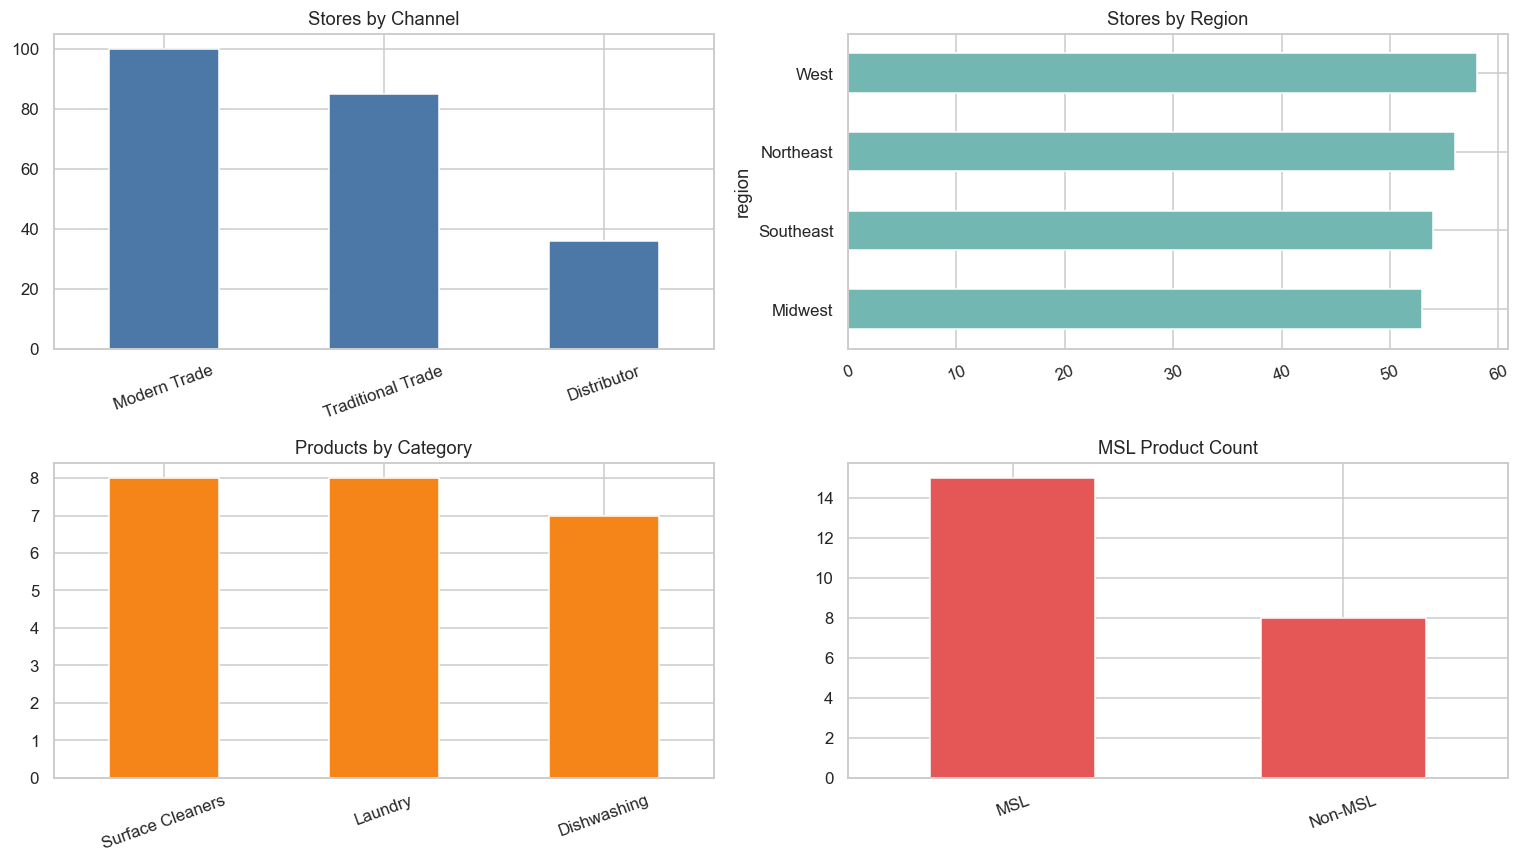

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

stores["channel"].value_counts().reindex(channel_order).plot.bar(
    ax=axes[0, 0], title="Stores by Channel", color="#4C78A8"
)
stores["region"].value_counts().sort_values().plot.barh(
    ax=axes[0, 1], title="Stores by Region", color="#72B7B2"
)
products["category"].value_counts().plot.bar(
    ax=axes[1, 0], title="Products by Category", color="#F58518"
)
products["is_msl"].value_counts().rename(index={True: "MSL", False: "Non-MSL"}).plot.bar(
    ax=axes[1, 1], title="MSL Product Count", color="#E45756"
)

for axis in axes.flat:
    axis.tick_params(axis="x", rotation=20)
    axis.set_xlabel("")
plt.tight_layout()
plt.show()


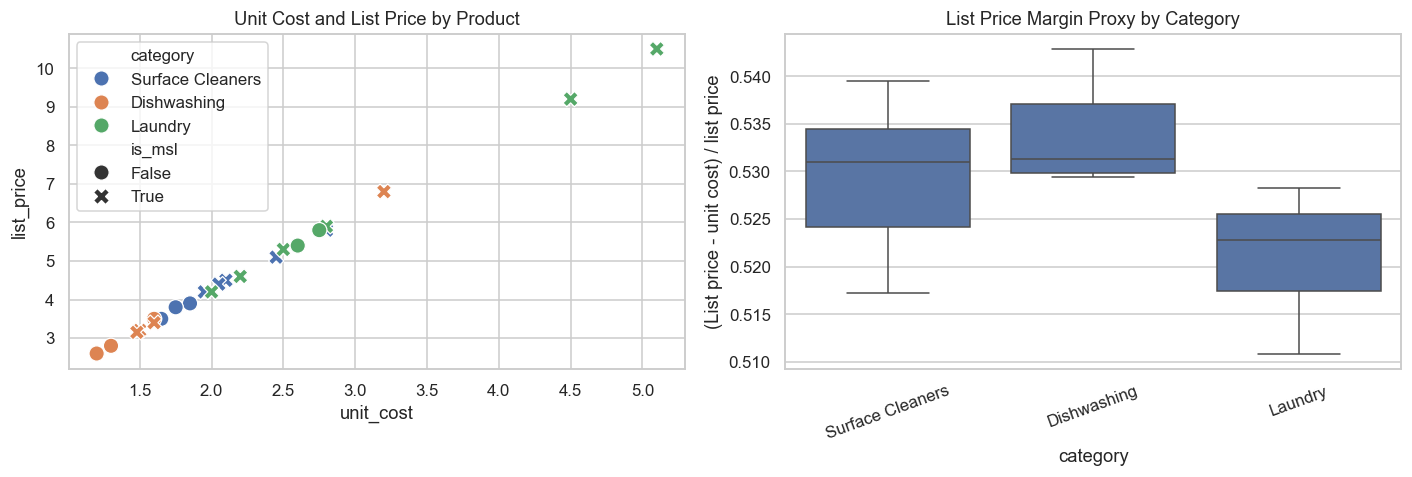

In [9]:
product_view = products.assign(
    gross_margin_proxy=(products["list_price"] - products["unit_cost"]) / products["list_price"]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(
    data=product_view,
    x="unit_cost",
    y="list_price",
    hue="category",
    style="is_msl",
    s=100,
    ax=axes[0],
)
axes[0].set_title("Unit Cost and List Price by Product")

sns.boxplot(data=product_view, x="category", y="gross_margin_proxy", ax=axes[1])
axes[1].set_title("List Price Margin Proxy by Category")
axes[1].set_ylabel("(List price - unit cost) / list price")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


**Interpretation caution:** The calculated product margin is only a proxy based on list price and unit cost. It is not an official commercial margin until the client confirms the margin formula and included costs.


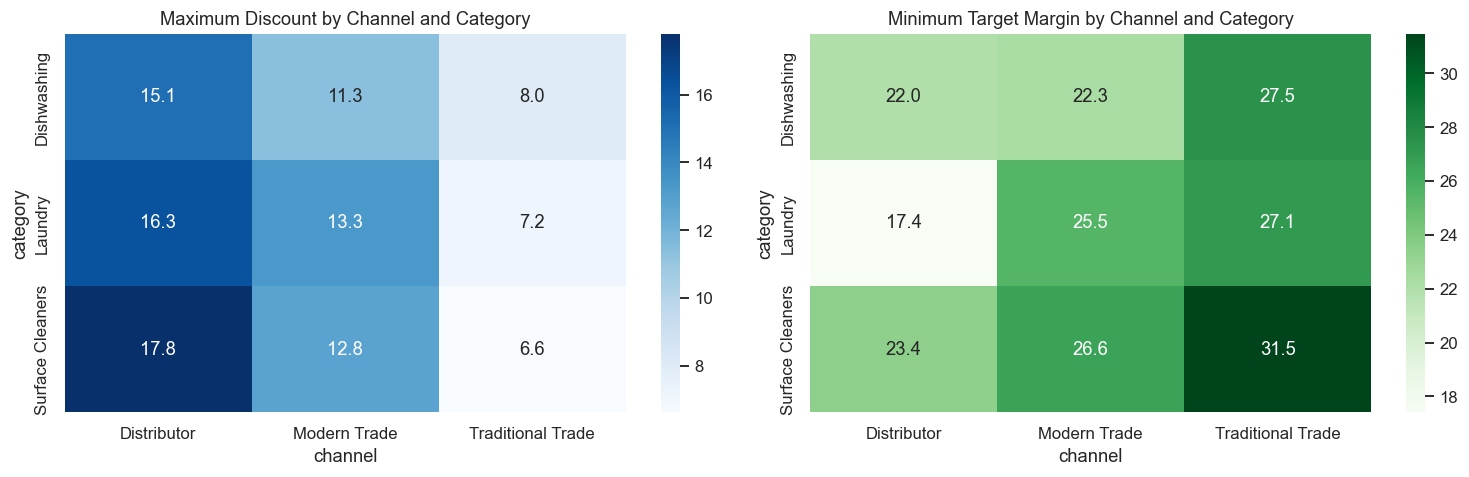

,channel,category,required_exec_tradeoff
0,Modern Trade,Surface Cleaners,Secure +10% shelf share or place 1 secondary d...
1,Modern Trade,Dishwashing,Commit to featured endcap placement for 4 weeks
2,Modern Trade,Laundry,Secure +15% shelf share or place 1 secondary d...
3,Traditional Trade,Surface Cleaners,Secure +10% shelf share or place 1 secondary d...
4,Traditional Trade,Dishwashing,Achieve 100% MSL compliance + planogram adherence
5,Traditional Trade,Laundry,Commit to featured endcap placement for 4 weeks
6,Distributor,Surface Cleaners,Achieve 100% MSL compliance + planogram adherence
7,Distributor,Dishwashing,Secure +15% shelf share or place 1 secondary d...
8,Distributor,Laundry,Commit to featured endcap placement for 4 weeks


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
max_discount = guardrails.pivot(index="category", columns="channel", values="max_discount_pct")
min_margin = guardrails.pivot(index="category", columns="channel", values="min_target_margin")

sns.heatmap(max_discount, annot=True, fmt=".1f", cmap="Blues", ax=axes[0])
axes[0].set_title("Maximum Discount by Channel and Category")
sns.heatmap(min_margin, annot=True, fmt=".1f", cmap="Greens", ax=axes[1])
axes[1].set_title("Minimum Target Margin by Channel and Category")
plt.tight_layout()
plt.show()

display(guardrails[["channel", "category", "required_exec_tradeoff"]])


## 6 Safe Dimension Joins


In [11]:
sell_in_enriched = (
    sell_in.merge(stores, on="store_id", how="left", validate="many_to_one")
    .merge(products, on="sku_id", how="left", validate="many_to_one")
)
sell_out_enriched = (
    sell_out.merge(stores, on="store_id", how="left", validate="many_to_one")
    .merge(products, on="sku_id", how="left", validate="many_to_one")
)
audits_enriched = (
    audits.merge(stores, on="store_id", how="left", validate="many_to_one")
    .merge(products, on="sku_id", how="left", validate="many_to_one")
)

join_checks = pd.DataFrame(
    [
        ["fact_sell_in", len(sell_in), len(sell_in_enriched)],
        ["fact_sell_out", len(sell_out), len(sell_out_enriched)],
        ["fact_execution_audits", len(audits), len(audits_enriched)],
    ],
    columns=["fact_table", "rows_before_join", "rows_after_join"],
)
join_checks["row_difference"] = join_checks["rows_after_join"] - join_checks["rows_before_join"]
display(join_checks)


,fact_table,rows_before_join,rows_after_join,row_difference
0,fact_sell_in,277969,277969,0
1,fact_sell_out,1656756,1656756,0
2,fact_execution_audits,207020,207020,0


These joins add store and product attributes without changing the row count. Fact tables should not be joined directly at their original grains. They must first be aggregated or aligned to a common date, store, and SKU grain.


## 7 Sell Out and OOS Patterns


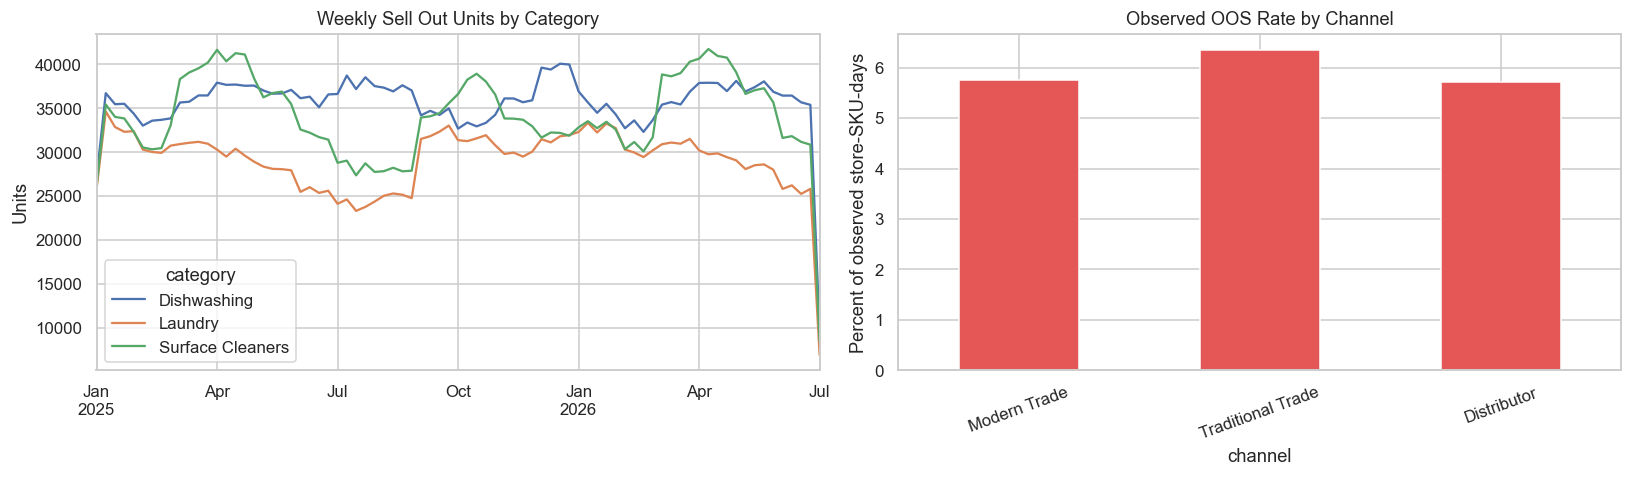

In [12]:
weekly_sell_out = (
    sell_out_enriched.set_index("date")
    .groupby([pd.Grouper(freq="W-SUN"), "category"])["units_sold_daily"]
    .sum()
    .unstack()
)

oos_summary = pd.DataFrame(
    {
        "channel": sell_out_enriched.groupby("channel")["is_out_of_stock"].mean(),
    }
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
weekly_sell_out.plot(ax=axes[0])
axes[0].set_title("Weekly Sell Out Units by Category")
axes[0].set_xlabel("")
axes[0].set_ylabel("Units")

channel_oos = sell_out_enriched.groupby("channel")["is_out_of_stock"].mean().reindex(channel_order) * 100
channel_oos.plot.bar(ax=axes[1], color="#E45756")
axes[1].set_title("Observed OOS Rate by Channel")
axes[1].set_ylabel("Percent of observed store-SKU-days")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


In [13]:
oos_breakdown = (
    sell_out_enriched.groupby(["channel", "segment_tier", "category"], observed=True)
    .agg(
        observed_rows=("is_out_of_stock", "size"),
        oos_rate=("is_out_of_stock", "mean"),
        average_inventory=("inventory_level", "mean"),
        average_daily_units=("units_sold_daily", "mean"),
    )
    .reset_index()
)
display(oos_breakdown.sort_values("oos_rate", ascending=False).head(15))


,channel,segment_tier,category,observed_rows,oos_rate,average_inventory,average_daily_units
25,Traditional Trade,Tier 3,Laundry,75676,0.08,9.29,0.99
16,Modern Trade,Tier 3,Laundry,61348,0.08,14.44,1.53
26,Traditional Trade,Tier 3,Surface Cleaners,68127,0.07,12.36,1.31
7,Distributor,Tier 3,Laundry,27474,0.07,12.37,1.30
8,Distributor,Tier 3,Surface Cleaners,24839,0.07,16.44,1.71
24,Traditional Trade,Tier 3,Dishwashing,62702,0.07,16.28,1.70
17,Modern Trade,Tier 3,Surface Cleaners,56347,0.07,19.59,2.04
22,Traditional Trade,Tier 2,Laundry,107649,0.06,24.25,2.53
6,Distributor,Tier 3,Dishwashing,22215,0.06,21.16,2.21
15,Modern Trade,Tier 3,Dishwashing,44896,0.06,25.26,2.61


## 8 Calendar Coverage


Observed store-days: 84,084
Possible calendar store-days: 120,666
Calendar coverage: 69.7%


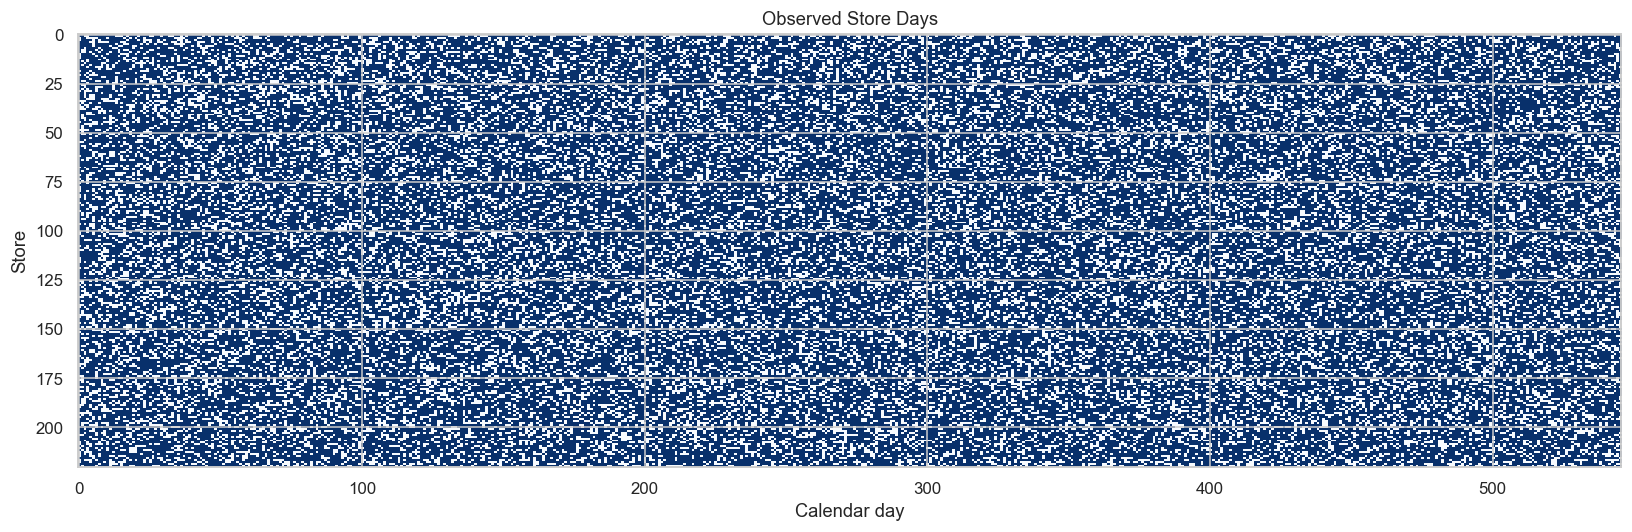

In [14]:
calendar = pd.date_range(sell_out["date"].min(), sell_out["date"].max(), freq="D")
observed_store_days = sell_out[["store_id", "date"]].drop_duplicates()
expected_store_days = stores["store_id"].nunique() * len(calendar)
coverage_rate = len(observed_store_days) / expected_store_days

print(f"Observed store-days: {len(observed_store_days):,}")
print(f"Possible calendar store-days: {expected_store_days:,}")
print(f"Calendar coverage: {coverage_rate:.1%}")

store_day_presence = (
    observed_store_days.assign(observed=1)
    .pivot(index="store_id", columns="date", values="observed")
    .reindex(columns=calendar)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(15, 5))
ax.imshow(store_day_presence, aspect="auto", interpolation="nearest", cmap="Blues")
ax.set_title("Observed Store Days")
ax.set_ylabel("Store")
ax.set_xlabel("Calendar day")
plt.tight_layout()
plt.show()


**Important:** An absent store-day is not automatically a zero-sales day. The client must confirm whether missing dates mean no activity, no reporting, or omitted records. Until then, calculations should describe them as unobserved days.


## 9 Sell In Patterns and Weekly Alignment


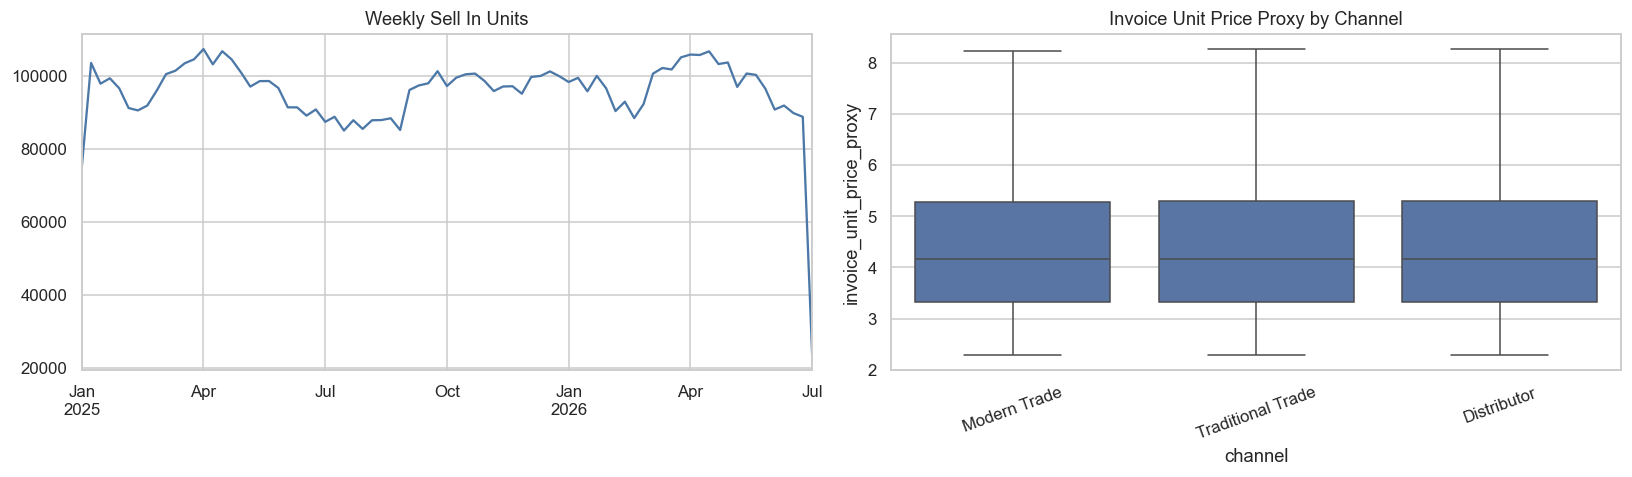

In [15]:
sell_in_enriched["invoice_unit_price_proxy"] = (
    sell_in_enriched["net_sales"] / sell_in_enriched["units_sold"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
weekly_sell_in = sell_in_enriched.set_index("date").resample("W-SUN")[["units_sold", "net_sales"]].sum()
weekly_sell_in["units_sold"].plot(ax=axes[0], color="#4C78A8")
axes[0].set_title("Weekly Sell In Units")
axes[0].set_xlabel("")

sns.boxplot(
    data=sell_in_enriched,
    x="channel",
    y="invoice_unit_price_proxy",
    order=channel_order,
    showfliers=False,
    ax=axes[1],
)
axes[1].set_title("Invoice Unit Price Proxy by Channel")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


**Interpretation caution:** `net_sales / units_sold` is an invoice unit price proxy. It should not be labeled as a discount or consumer price until the client confirms what `net_sales` includes.


In [16]:
sell_in_weekly = (
    sell_in.assign(week_start=lambda frame: frame["date"] - pd.to_timedelta(frame["date"].dt.dayofweek, unit="D"))
    .groupby(["week_start", "store_id", "sku_id"], as_index=False)
    .agg(sell_in_units=("units_sold", "sum"), sell_in_net_sales=("net_sales", "sum"))
)

sell_out_weekly = (
    sell_out.assign(week_start=lambda frame: frame["date"] - pd.to_timedelta(frame["date"].dt.dayofweek, unit="D"))
    .groupby(["week_start", "store_id", "sku_id"], as_index=False)
    .agg(
        observed_sell_out_units=("units_sold_daily", "sum"),
        observed_days=("date", "nunique"),
        observed_oos_rate=("is_out_of_stock", "mean"),
    )
)

weekly_comparison = sell_in_weekly.merge(
    sell_out_weekly,
    on=["week_start", "store_id", "sku_id"],
    how="outer",
    validate="one_to_one",
)
weekly_comparison = weekly_comparison.merge(
    stores[["store_id", "channel", "region", "segment_tier"]],
    on="store_id",
    how="left",
    validate="many_to_one",
).merge(
    products[["sku_id", "category", "is_msl"]],
    on="sku_id",
    how="left",
    validate="many_to_one",
)

display(weekly_comparison.head())


,week_start,store_id,sku_id,sell_in_units,sell_in_net_sales,observed_sell_out_units,observed_days,observed_oos_rate,channel,region,segment_tier,category,is_msl
0,2024-12-30,STR-0001,SKU-1001,5.00,20.88,5,4,0.00,Modern Trade,Northeast,Tier 3,Surface Cleaners,True
1,2024-12-30,STR-0001,SKU-1002,7.00,28.79,6,4,0.00,Modern Trade,Northeast,Tier 3,Surface Cleaners,True
2,2024-12-30,STR-0001,SKU-1004,8.00,43.61,8,4,0.00,Modern Trade,Northeast,Tier 3,Surface Cleaners,True
3,2024-12-30,STR-0001,SKU-1006,14.00,52.30,13,4,0.00,Modern Trade,Northeast,Tier 3,Surface Cleaners,True
4,2024-12-30,STR-0001,SKU-1008,9.00,40.68,8,4,0.00,Modern Trade,Northeast,Tier 3,Surface Cleaners,True


The weekly table creates a comparable grain for sell-in and sell-out. However, the sell-out total covers only observed days. A sell-in versus sell-out gap should not become an official KPI until the client confirms how missing sell-out days should be handled and whether the units are directly comparable.


## 10 Execution Audit Patterns


,channel,segment_tier,audit_rows,planogram_compliance,average_shelf_share,secondary_display_rate
0,Distributor,Tier 1,24831,0.87,37.98,0.65
1,Distributor,Tier 2,7406,0.72,28.04,0.40
2,Distributor,Tier 3,3890,0.54,18.12,0.22
3,Modern Trade,Tier 1,67814,0.95,43.00,0.55
4,Modern Trade,Tier 2,27070,0.81,32.99,0.30
5,Modern Trade,Tier 3,8268,0.61,22.99,0.12
6,Traditional Trade,Tier 1,27007,0.87,38.01,0.55
7,Traditional Trade,Tier 2,30204,0.73,28.06,0.30
8,Traditional Trade,Tier 3,10530,0.53,18.02,0.12


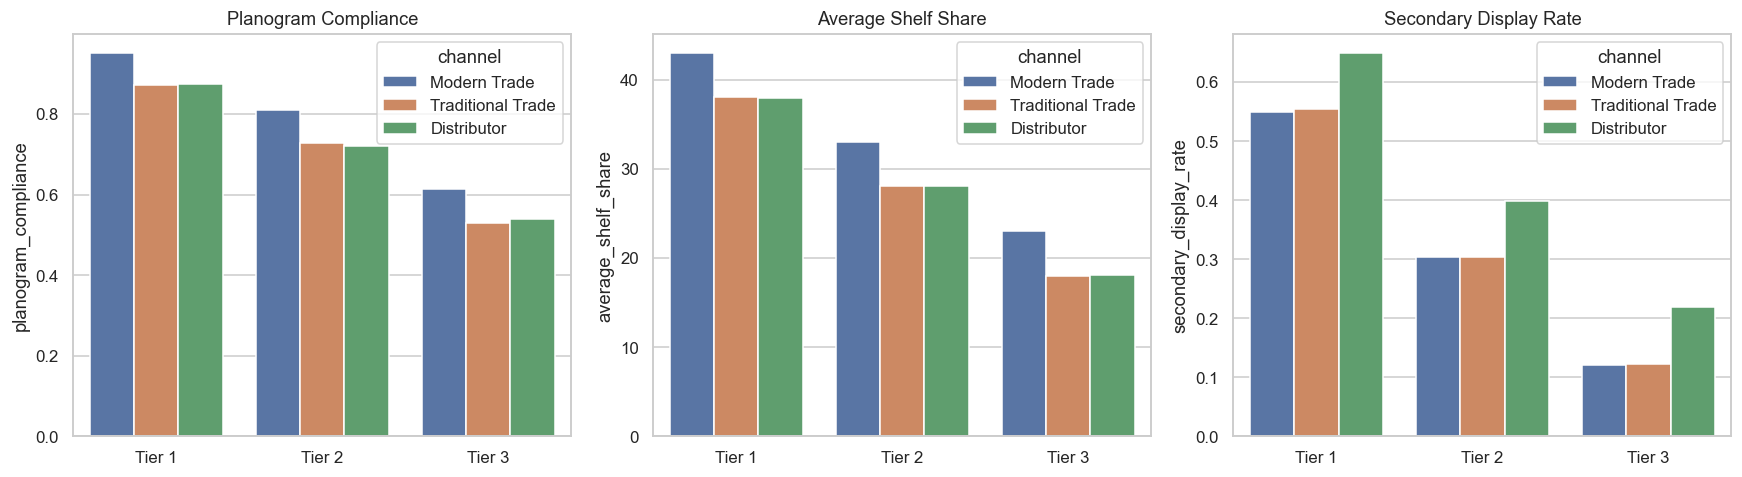

In [17]:
execution_summary = (
    audits_enriched.groupby(["channel", "segment_tier"], observed=True)
    .agg(
        audit_rows=("audit_id", "size"),
        planogram_compliance=("planogram_compliance", "mean"),
        average_shelf_share=("shelf_share_pct", "mean"),
        secondary_display_rate=("secondary_display", "mean"),
    )
    .reset_index()
)
display(execution_summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics = [
    ("planogram_compliance", "Planogram Compliance"),
    ("average_shelf_share", "Average Shelf Share"),
    ("secondary_display_rate", "Secondary Display Rate"),
]

for axis, (metric, title) in zip(axes, metrics):
    sns.barplot(
        data=execution_summary,
        x="segment_tier",
        y=metric,
        hue="channel",
        order=tier_order,
        hue_order=channel_order,
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel("")
plt.tight_layout()
plt.show()


## 11 Audit and Sell Out Join Availability


In [18]:
audit_sales_same_day = audits.merge(
    sell_out[["date", "store_id", "sku_id", "units_sold_daily", "inventory_level", "is_out_of_stock"]],
    on=["date", "store_id", "sku_id"],
    how="left",
    validate="many_to_one",
    indicator=True,
)

match_rate = audit_sales_same_day["_merge"].eq("both").mean()
print(f"Audit rows with a same-day sell-out record: {match_rate:.1%}")

display(
    audit_sales_same_day["_merge"]
    .value_counts(dropna=False)
    .rename_axis("join_result")
    .to_frame("rows")
)


Audit rows with a same-day sell-out record: 70.0%


,rows
join_result,
both,144904
left_only,62116
right_only,0


A same-day join measures data availability, not the causal impact of execution. Any later analysis of planogram, shelf share, or secondary displays should define a time window and control for store, product, seasonality, inventory, and store tier.


## 12 Initial Findings

- The six tables use consistent store and SKU identifiers.
- The fact tables can be safely enriched with store and product dimensions using many-to-one joins.
- Sell-in and sell-out use different time frequencies and must be aligned before comparison.
- Sell-out does not cover every calendar store-day. Missing dates must remain labeled as unobserved until the client explains them.
- The OOS flag can be checked against zero inventory, but the inventory timing still needs confirmation.
- Sell-out does not contain consumer price or revenue, which limits price-elasticity and sell-out revenue analysis.
- Audit variables can be joined to sales data, but descriptive association must not be presented as causal impact.


## 13 Questions for the Client

1. What does one row represent in each fact table?
2. Do missing sell-out dates mean zero activity, missing reporting, or intentionally omitted records?
3. Is `inventory_level` measured at the beginning or end of the day?
4. Is `is_out_of_stock` defined only by `inventory_level == 0`?
5. Are sell-in and sell-out units directly comparable?
6. How should weekly sell-in dates align with daily sell-out dates?
7. What is the official definition of the sell-in versus sell-out gap?
8. What is the official definition of MSL compliance?
9. What is the official definition of planogram compliance?
10. Does `max_discount_pct` mean the total allowed discount or an additional discount?
11. What costs are included in the target margin calculation?
12. Can the client provide consumer price, promotion, margin, or field representative data?
13. For Module 2, does the target mean OOS exactly at day 7 or at any time during the next 7 days?


## 14 Next Steps

1. Confirm the open definitions with the client.
2. Update the data dictionary with confirmed business meanings.
3. Agree on the official KPI calculations.
4. Create a separate feature-engineering and modeling notebook for Module 2.
5. Create a separate dashboard dataset after the KPI definitions are approved.
